# 02 · Features and models

Can network topology alone tell us which proteins interact? This notebook follows the pipeline in
`src/model.py` step by step:

1. hide 10% of interactions as a test set (and another 10% for training) with the leakage-free protocol;
2. compute topological features for each candidate pair on a graph **without** that pair's edge;
3. compare how individual features separate interactions from non-interactions;
4. train and evaluate the classifiers, and stress-test them with harder negatives.

The data is the preprocessed **HI-III** human interactome (5,216 proteins, 22,195 binary interactions from
a systematic yeast two-hybrid screen; see notebook 01). Notebook 01 found that in this map interacting
proteins share *fewer* partners than expected by chance but are linked by *more* paths of length three. This
notebook tests what that means for prediction.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from src.evaluate import (
    INK, PALETTE, compute_permutation_importance, display_name, evaluate_scores,
    heuristic_scores, plot_feature_importance, plot_pr_curves, plot_roc_curves, plot_style,
)
from src.graph_builder import load_graph, make_link_prediction_split
from src.model import PipelineConfig, build_feature_matrices, rank_novel_interactions, train_models
from src.preprocessing import load_symbol_map, processed_path

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)

SEED = 42
DATA = processed_path("hi-iii")  # downloads and preprocesses on first use
G = load_graph(DATA)
symbols = load_symbol_map(DATA)
config = PipelineConfig(seed=SEED)  # betweenness: 1,000 sampled sources for networks > 3,000 proteins
print(f"{G.number_of_nodes():,} proteins, {G.number_of_edges():,} interactions")

5,216 proteins, 22,195 interactions


## 1. Leakage-free split

`make_link_prediction_split` hides two disjoint sets of interactions. Test pairs are featurised on
`test_graph` (= network − test edges) and training pairs on `train_graph` (= network − test − training
edges). A pair's own edge is therefore never visible when its features are computed, which is the most
common source of inflated link-prediction results. A random spanning tree is protected so no protein becomes
isolated. Negatives are protein pairs with no recorded interaction.

In [2]:
split = make_link_prediction_split(G, test_fraction=0.1, train_fraction=0.1, seed=SEED)
pd.Series(split.summary(), name="count").to_frame()

,count
train_graph_edges,17755
test_graph_edges,19975
train_positives,2220
train_negatives,2220
test_positives,2220
test_negatives,2220


In [3]:
X_train, X_test = build_feature_matrices(split, config)
y_train, y_test = split.train_labels, split.test_labels
X_train.assign(label=y_train).head()

,degree_min,degree_max,clustering_min,clustering_max,betweenness_min,betweenness_max,closeness_min,closeness_max,common_neighbors,jaccard,adamic_adar,resource_allocation,preferential_attachment,l3,shortest_path,label
0,17.0,22.0,0.082,0.088,2.884e-04,5.992e-04,0.276,0.311,0.0,0.0,0.0,0.0,374.0,0.892,3.0,1
1,3.0,32.0,0.000,0.010,1.933e-04,2.816e-03,0.227,0.296,0.0,0.0,0.0,0.0,96.0,0.082,3.0,1
2,12.0,98.0,0.000,0.004,1.114e-03,2.081e-02,0.294,0.325,0.0,0.0,0.0,0.0,1176.0,0.917,3.0,1
3,2.0,103.0,0.000,0.008,1.486e-06,2.739e-02,0.252,0.343,0.0,0.0,0.0,0.0,206.0,0.342,3.0,1
4,2.0,22.0,0.000,0.061,6.592e-06,3.715e-03,0.243,0.319,0.0,0.0,0.0,0.0,44.0,0.938,3.0,1


## 2. How well does each feature separate the classes?

Distributions for interacting (label 1) and non-interacting (label 0) training pairs, on a `log1p` scale
for the count-like features.

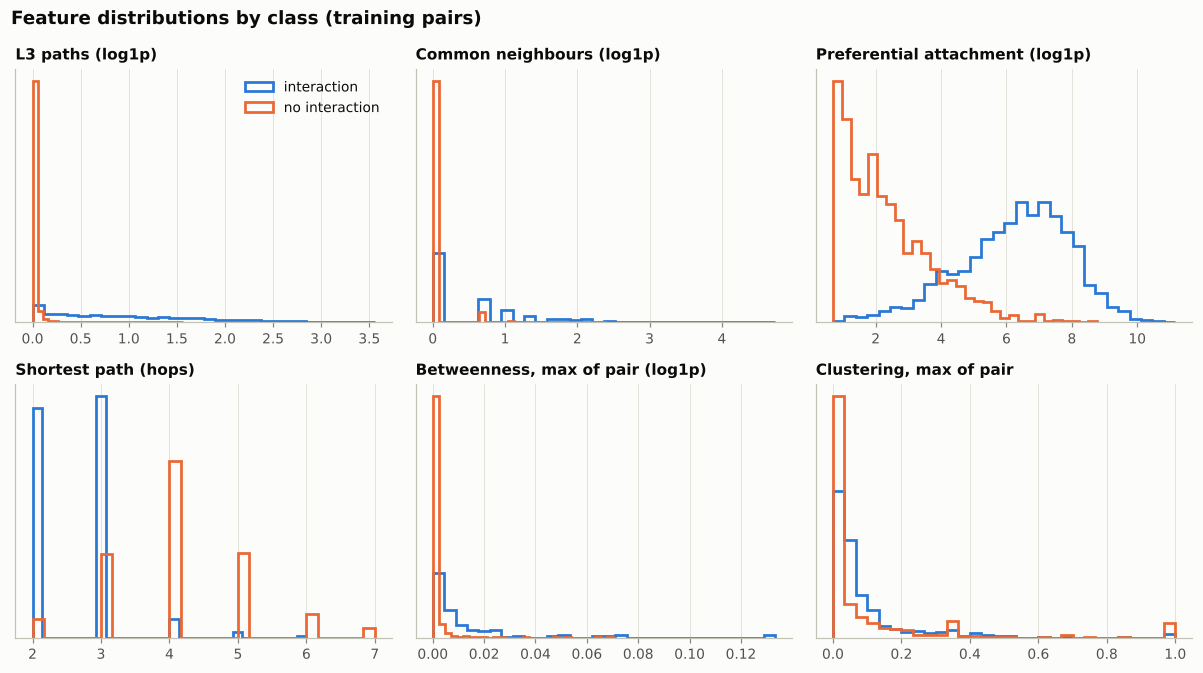

In [4]:
shown = {
    "l3": "L3 paths (log1p)",
    "common_neighbors": "Common neighbours (log1p)",
    "preferential_attachment": "Preferential attachment (log1p)",
    "shortest_path": "Shortest path (hops)",
    "betweenness_max": "Betweenness, max of pair (log1p)",
    "clustering_max": "Clustering, max of pair",
}
labels = np.where(y_train == 1, "interaction", "no interaction")

with plot_style():
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
    for ax, (feature, title) in zip(axes.ravel(), shown.items()):
        values = X_train[feature]
        if feature not in ("shortest_path", "clustering_max"):
            values = np.log1p(values)
        for colour, cls in zip(PALETTE, ["interaction", "no interaction"]):
            ax.hist(values[labels == cls], bins=30, histtype="step", linewidth=1.8,
                    color=colour, density=True, label=cls)
        ax.set_title(title, fontsize=10)
        ax.set_yticks([])
        ax.grid(axis="y", visible=False)
    axes[0, 0].legend(loc="upper right")
    fig.suptitle("Feature distributions by class (training pairs)", x=0.01, ha="left",
                 fontweight="bold", color=INK["primary"])
    fig.tight_layout()
    plt.show()

**Paths of length three beat shared partners.** Only about half of the hidden HI-III interactions have even
one common neighbour, but 96% are connected by at least one path of length three. For non-interacting pairs
the figures are 6% and 31% (table below). This is the L3 principle of Kovács et al. (2019): two proteins
interact when one resembles the other's partners (a shared binding interface), so they are linked through
each other's partners by paths of length three rather than by shared partners.

The preferential-attachment panel shows a second strong signal. In this Y2H map the hubs from notebook 01 take
part in a large share of all interactions, so pairs that involve a hub are much more likely to interact.

In [5]:
pos, neg = X_test[y_test == 1], X_test[y_test == 0]
pd.DataFrame({
    "held-out interactions": [(pos.common_neighbors > 0).mean(), (pos.l3 > 0).mean()],
    "non-interacting pairs": [(neg.common_neighbors > 0).mean(), (neg.l3 > 0).mean()],
}, index=["share with ≥1 common neighbour", "connected by ≥1 path of length 3"])

,held-out interactions,non-interacting pairs
share with ≥1 common neighbour,0.541,0.057
connected by ≥1 path of length 3,0.956,0.306


## 3. Feature redundancy

Spearman correlations between features. Node-level metrics (degree, betweenness, closeness) are strongly
correlated with each other and with preferential attachment, as are the neighbourhood-overlap scores.
Tree models handle such redundancy well; it also means permutation importance (section 6) spreads credit
unevenly across correlated features.

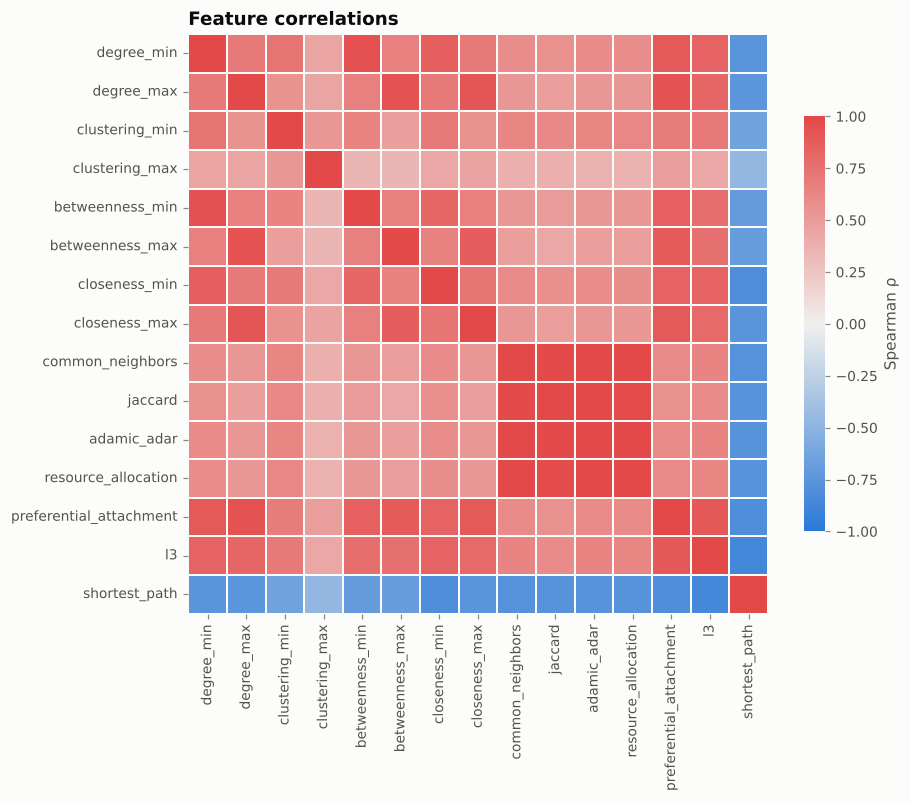

In [6]:
corr = X_train.corr(method="spearman")
diverging = LinearSegmentedColormap.from_list("blue_red", [PALETTE[0], "#f0efec", PALETTE[7]])

with plot_style():
    fig, ax = plt.subplots(figsize=(8.5, 7))
    sns.heatmap(corr, cmap=diverging, vmin=-1, vmax=1, center=0, square=True, linewidths=1,
                linecolor=INK["surface"], cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
    ax.grid(False)
    ax.set_title("Feature correlations")
    plt.show()

## 4. Train and evaluate

Three classifiers are cross-validated on the training pairs (5-fold stratified) and then scored on the
held-out test pairs, next to unsupervised heuristics that rank pairs by a single feature.

In [7]:
models = train_models(X_train, y_train, seed=SEED, cv_folds=5)
model_scores = {name: m.predict_proba(X_test) for name, m in models.items()}
baselines = heuristic_scores(X_test)
uniform_metrics = evaluate_scores(y_test, model_scores, baselines)
uniform_metrics[["kind", "roc_auc", "average_precision", "r_precision", "f1", "mcc"]]

,kind,roc_auc,average_precision,r_precision,f1,mcc
method,,,,,,
gradient_boosting,model,0.972,0.973,0.922,0.921,0.842
logistic_regression,model,0.971,0.973,0.914,0.914,0.830
random_forest,model,0.971,0.971,0.924,0.922,0.842
l3,heuristic,0.958,0.963,0.918,NaN,NaN
preferential_attachment,heuristic,0.957,0.957,0.891,NaN,NaN
shortest_path,heuristic,0.882,0.826,0.789,NaN,NaN
adamic_adar,heuristic,0.751,0.755,0.684,NaN,NaN
resource_allocation,heuristic,0.751,0.752,0.684,NaN,NaN
common_neighbors,heuristic,0.749,0.745,0.684,NaN,NaN


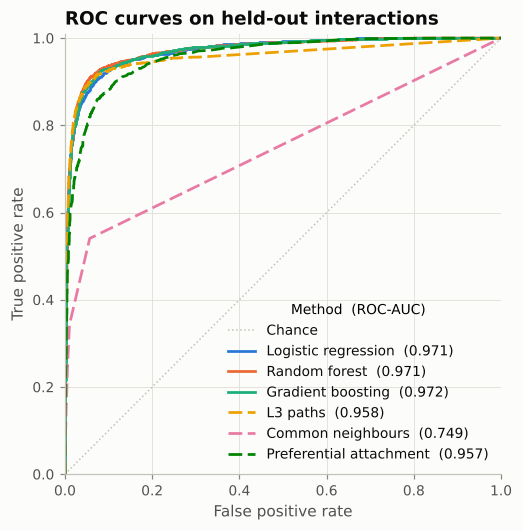

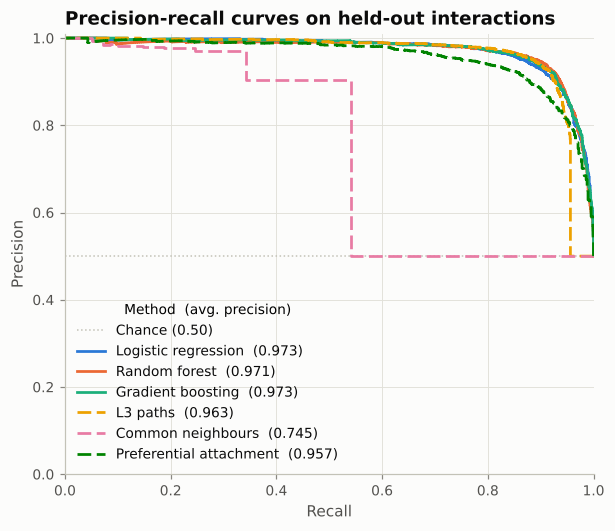

In [8]:
kinds = {**{n: "model" for n in model_scores}, **{n: "heuristic" for n in baselines}}
plotted = {**model_scores, **{n: baselines[n] for n in ["l3", "common_neighbors", "preferential_attachment"]}}
plot_roc_curves(y_test, plotted, kinds)
plt.show()
plot_pr_curves(y_test, plotted, kinds)
plt.show()

All three classifiers reach ROC-AUC ≈ 0.97 and improve on the best heuristic, L3 (0.958). Preferential
attachment is a close second (0.957): with uniform negatives, simply pairing hubs is a strong rule on a
hub-dominated Y2H map. The common-neighbour scores (common neighbours, Adamic-Adar, resource allocation,
Jaccard) trail at 0.74-0.75, consistent with the depletion of shared partners found in notebook 01. The
models gain most over L3 at high recall, where L3 runs out of information (4% of true interactions have no
length-3 path) and the models fall back on degree, distance and centrality.

## 5. Harder negatives

Uniformly sampled negatives are mostly far apart in the network, which flatters every method: a pair four
hops apart is easy to reject. Sampling negatives two or three steps apart (`negative_strategy="local"`)
gives a more conservative, realistic estimate.

In [9]:
local_split = make_link_prediction_split(G, seed=SEED, negative_strategy="local")
X_train_l, X_test_l = build_feature_matrices(local_split, config)
local_models = train_models(X_train_l, local_split.train_labels, seed=SEED, cv_folds=0)
local_metrics = evaluate_scores(
    local_split.test_labels,
    {name: m.predict_proba(X_test_l) for name, m in local_models.items()},
    heuristic_scores(X_test_l),
)

comparison = pd.DataFrame({
    "uniform negatives": uniform_metrics["roc_auc"],
    "local negatives": local_metrics["roc_auc"],
}).sort_values("local negatives", ascending=False)
comparison

,uniform negatives,local negatives
method,,
gradient_boosting,0.972,0.934
random_forest,0.971,0.932
logistic_regression,0.971,0.925
l3,0.958,0.872
preferential_attachment,0.957,0.852
common_neighbors,0.749,0.527
adamic_adar,0.751,0.503
resource_allocation,0.751,0.468
shortest_path,0.882,0.441


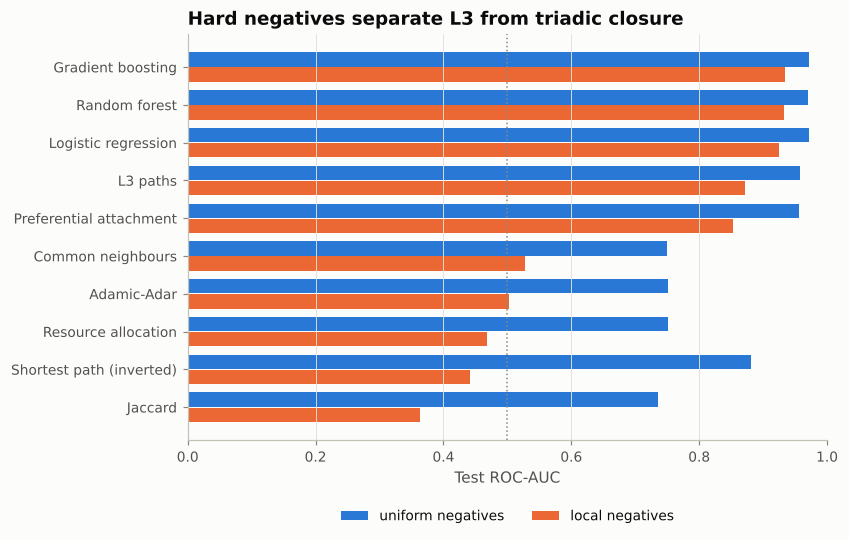

In [10]:
with plot_style():
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    y = np.arange(len(comparison))
    ax.barh(y - 0.2, comparison["uniform negatives"], height=0.38, color=PALETTE[0], label="uniform negatives")
    ax.barh(y + 0.2, comparison["local negatives"], height=0.38, color=PALETTE[1], label="local negatives")
    ax.axvline(0.5, color=INK["muted"], linewidth=1, linestyle=":")
    ax.set_yticks(y, [display_name(n) for n in comparison.index])
    ax.invert_yaxis()
    ax.set(xlim=(0, 1), xlabel="Test ROC-AUC")
    ax.grid(axis="y", visible=False)
    ax.set_title("Hard negatives separate L3 from triadic closure")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
    plt.show()

With local negatives every method loses performance, but not equally. The common-neighbour scores fall to
chance (0.47-0.53), and Jaccard and shortest path fall *below* chance: non-interacting proteins two or three
steps apart share partners and are as close as true interactors. L3 holds at 0.87, preferential attachment
drops to 0.85, and the classifiers keep ROC-AUC ≈ 0.93 by combining the two. Reporting both protocols,
rather than only the flattering one, is good practice.

## 6. What the best model relies on

Permutation importance: the drop in test ROC-AUC when one feature is shuffled.

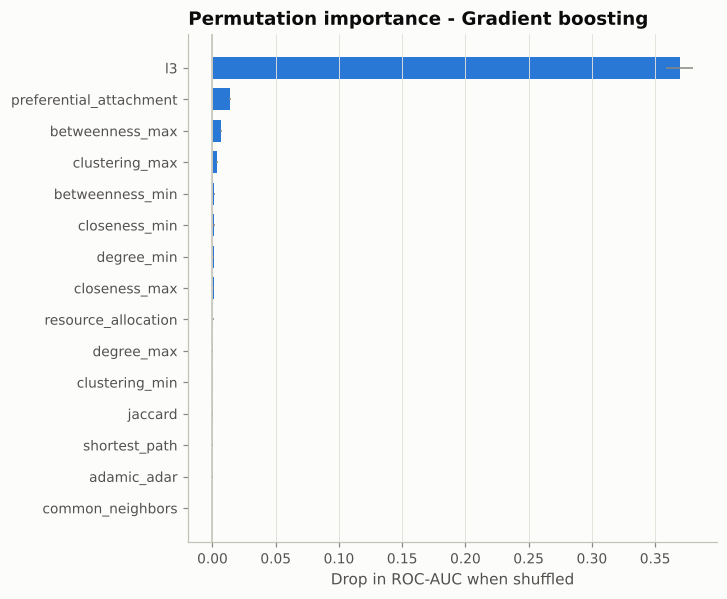

,feature,importance_mean,importance_std
0,l3,0.369,1.047e-02
1,preferential_attachment,0.014,7.429e-04
2,betweenness_max,0.007,7.662e-04
3,clustering_max,0.003,7.952e-04
4,betweenness_min,0.001,4.017e-04
5,closeness_min,0.001,5.363e-04


In [11]:
best = uniform_metrics[uniform_metrics.kind == "model"].roc_auc.idxmax()
importance = compute_permutation_importance(models[best].estimator, X_test, y_test, n_repeats=10, seed=SEED)
plot_feature_importance(importance, title=f"Permutation importance - {display_name(best)}")
plt.show()
importance.head(6)

L3 dominates: shuffling it costs the model 0.37 ROC-AUC, more than 25 times any other feature. Correlated
features (degree, centralities, preferential attachment) share information, so shuffling any single one costs
little, even though together they carry the signal used at high recall.

## 7. Candidate novel interactions

The best model is applied to currently unobserved pairs (pre-selected by L3 on the full network) to propose
interactions for experimental follow-up.

In [12]:
ranked = rank_novel_interactions(G, models[best], top_k=5000, n_candidates=5000,
                                 extractor=config.extractor(G.number_of_nodes()), symbols=symbols)
degree = dict(G.degree())
hub_cut = np.quantile(list(degree.values()), 0.99)
ranked["involves_top1pct_hub"] = [degree[a] >= hub_cut or degree[b] >= hub_cut
                                  for a, b in zip(ranked.protein_a, ranked.protein_b)]
columns = ["symbol_a", "symbol_b", "probability", "l3", "common_neighbors"]
top100 = ranked.head(100)
print(f"{top100.involves_top1pct_hub.mean():.0%} of the top 100 predictions involve a top-1% hub "
      f"(degree >= {hub_cut:.0f})")
top100.head(15)[columns]

93% of the top 100 predictions involve a top-1% hub (degree >= 92)


,symbol_a,symbol_b,probability,l3,common_neighbors
0,KRTAP10-7,TNS2,1.0,8.415,11.0
1,KRTAP1-1,TRIM41,1.0,8.739,10.0
2,AES,LONRF1,1.0,8.125,9.0
3,KRTAP10-8,KANK2,1.0,18.959,15.0
4,KRTAP10-8,KIFC3,1.0,13.768,16.0
5,SCNM1,TRIM41,1.0,8.356,9.0
6,NOTCH2NL,TRIM41,1.0,9.112,10.0
7,KRTAP12-3,AES,1.0,13.059,10.0
8,KIFC3,RINT1,1.0,7.423,9.0
9,KIFC3,C1orf216,1.0,7.058,10.0


The top predictions have probabilities close to 1, and almost all involve a top-1% hub, mostly
keratin-associated proteins (KRTAP10-3, KRTAP10-8) and frequent Y2H partners such as KANK2, KIFC3 and TRIM41. Hubs
with hundreds of partners also accumulate the most length-3 paths, so these predictions extend known hub
neighbourhoods rather than point to independent discoveries. For follow-up it is more informative to look at
the best-ranked pairs that avoid the largest hubs:

In [13]:
ranked[~ranked.involves_top1pct_hub].head(10)[columns]

,symbol_a,symbol_b,probability,l3,common_neighbors
5,SCNM1,TRIM41,1.000,8.356,9.0
24,ZNF408,KRTAP2-4,1.000,10.614,8.0
32,SCNM1,NAB2,1.000,10.570,8.0
47,LCE1D,KRTAP10-6,1.000,9.498,12.0
63,KRTAP4-12,KRTAP10-6,1.000,8.124,9.0
74,CCDC120,SPERT,1.000,7.425,7.0
79,SCNM1,TNS2,1.000,7.248,8.0
150,HOXA1,EFEMP2,0.999,9.395,7.0
166,NAB2,BYSL,0.999,8.421,5.0
196,CATSPER1,KRTAP10-6,0.999,9.418,7.0


These candidates are still supported by many length-3 paths but do not depend on a single promiscuous
protein. They are the kind of prediction worth testing in a pairwise binding assay.

## Conclusions

* On the real HI-III interactome, topology alone predicts held-out interactions with ROC-AUC 0.97 (uniform
  negatives) and 0.93 (hard local negatives).
* L3 paths are the most informative single feature, in line with the complementarity principle and the
  closure analysis in notebook 01. Triadic-closure scores are weak and fall to chance against hard negatives.
* Supervised models add value by combining L3 with degree, distance and centrality, most clearly against hard
  negatives (+0.06 ROC-AUC over L3).
* Caveats: a held-out edge from the same screen is an easier target than a truly new interaction, and
  predictions inherit the hub structure and assay biases of the Y2H map, so candidates need experimental
  validation. `src/benchmark.py` repeats the evaluation on three more interactomes (`reports/benchmark/`).